# 07 · Test-set Evaluation, SHAP, Equity

Evaluate on the five TEST storms (Ida, Ian, Idalia, Helene, Milton; 2021–2024), never used for training, selection, or calibration. Class predictions use the raw classifier; probabilities for the priority index use the VAL-fit isotonic calibrator.

In [1]:
import sys, os
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', 60)
from config import (
    DATA_PATHS, HURRICANE_META, STATES_IN_SCOPE,
    TARGET_COL, TARGET_CLASS_COL, FEATURE_GROUPS,
    RANDOM_STATE, SEVERITY_BINS, SEVERITY_LABELS,
)
RAW = DATA_PATHS['raw']; INTERIM = DATA_PATHS['interim']
PROC = DATA_PATHS['processed']; MODELS = DATA_PATHS['models']
OUT = DATA_PATHS['outputs']


In [2]:
import joblib, shap
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             mean_squared_error, mean_absolute_error, r2_score)
from src.evaluation import equity_audit, svi_quartile, shap_mean_abs_by_group
pkg = joblib.load(MODELS / 'best_classifier.pkl')
pipe, calibrator, le, features = pkg['pipe'], pkg['calibrator'], pkg['label_encoder'], pkg['features']
df = pd.read_csv(PROC / 'abt.csv', dtype={'zip_code': str}).dropna(subset=[TARGET_CLASS_COL])
# reset_index: notebook 08 and the dashboard rely on this exact TEST row order
te = df[df['train_test_split'] == 'TEST'].reset_index(drop=True)
Xte = te[features]; yte = le.transform(te[TARGET_CLASS_COL])

/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Classification metrics

In [3]:
pred = pipe.predict(Xte)
proba, proba_cal = pipe.predict_proba(Xte), calibrator.predict_proba(Xte)
print(classification_report(yte, pred, target_names=le.classes_, digits=3, zero_division=0))
onehot = np.eye(len(le.classes_))[yte]
print('macro ROC-AUC:', round(roc_auc_score(onehot, proba, average='macro'), 3))
for tag, p in [('raw', proba), ('isotonic', proba_cal)]:
    print(f'multiclass Brier ({tag}):', round(((p - onehot) ** 2).mean(), 3))

              precision    recall  f1-score   support

        High      0.299     0.200     0.239       541
         Low      0.772     0.839     0.804       862
      Medium      0.426     0.178     0.251       471
      Severe      0.520     0.797     0.629       713

    accuracy                          0.573      2587
   macro avg      0.504     0.503     0.481      2587
weighted avg      0.541     0.573     0.537      2587

macro ROC-AUC: 0.784
multiclass Brier (raw): 0.164
multiclass Brier (isotonic): 0.141


/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


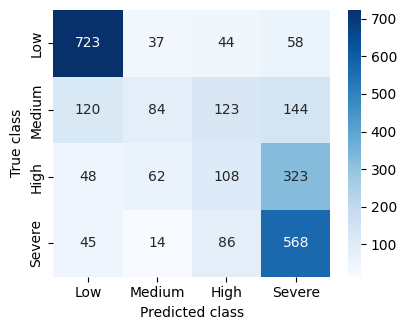

In [4]:
order = [list(le.classes_).index(c) for c in SEVERITY_LABELS]  # Low -> Severe
cm = confusion_matrix(yte, pred)[np.ix_(order, order)]
fig, ax = plt.subplots(figsize=(4.2, 3.4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=SEVERITY_LABELS,
            yticklabels=SEVERITY_LABELS, ax=ax)
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
plt.tight_layout(); plt.savefig(OUT / 'test_confusion.png', dpi=300); plt.show()

## Regression metrics (per hurricane)

In [5]:
pkgR = joblib.load(MODELS / 'best_regressor.pkl')
te['yhat'] = pkgR['pipe'].predict(Xte)
for hn, sub in te.groupby('hurricane_name'):
    rmse = np.sqrt(mean_squared_error(sub[TARGET_COL], sub['yhat']))
    mae = mean_absolute_error(sub[TARGET_COL], sub['yhat'])
    r2 = r2_score(sub[TARGET_COL], sub['yhat'])
    print(f'{hn}: RMSE={rmse:.2f} MAE={mae:.2f} R2={r2:.3f}')

/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Helene: RMSE=48.06 MAE=30.29 R2=-0.086
Ian: RMSE=48.92 MAE=20.61 R2=0.171
Ida: RMSE=162.23 MAE=92.76 R2=-0.171
Idalia: RMSE=171.97 MAE=24.50 R2=0.062
Milton: RMSE=19.33 MAE=9.15 R2=0.355


## SHAP — tree explainer on the preprocessed matrix

In [6]:
pre = pipe.named_steps['pre']; model = pipe.named_steps['model']
Xte_t = pre.transform(Xte)
Xte_t = Xte_t.toarray() if hasattr(Xte_t, 'toarray') else Xte_t
feat_names = [n.split('__', 1)[1] for n in pre.get_feature_names_out()]
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(Xte_t)
# multi-class: list[n_classes] or ndarray (n, features, classes)
sv_arr = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
severe_idx = list(le.classes_).index('Severe')
np.save(OUT / 'shap_values.npy', sv_arr)
print('sv shape', sv_arr.shape)

/Users/anees/.pyenv/versions/3.11.8/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


sv shape (2587, 32, 4)


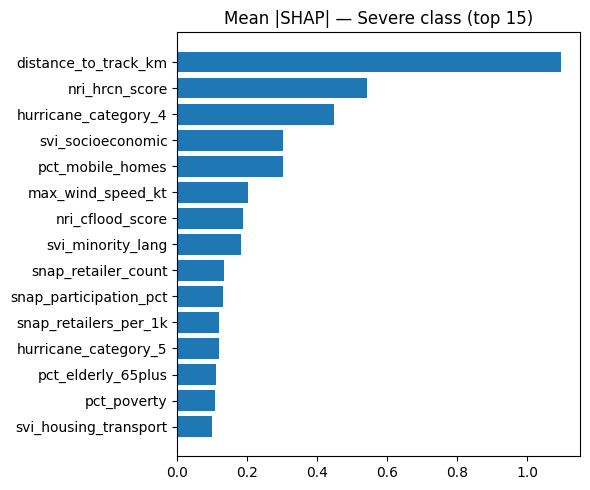

In [7]:
shap.summary_plot(sv_arr[:, :, severe_idx], Xte_t, feature_names=feat_names, show=False,
                  max_display=10, plot_size=(6, 3.8))
plt.savefig(OUT / 'shap_beeswarm_severe.png', dpi=300, bbox_inches='tight'); plt.close()
mabs = np.abs(sv_arr[:, :, severe_idx]).mean(axis=0)
top = np.argsort(mabs)[-15:]
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(np.array(feat_names)[top], mabs[top])
ax.set_title('Mean |SHAP| — Severe class (top 15)')
plt.tight_layout(); plt.savefig(OUT / 'shap_global_severe.png', dpi=150); plt.show()

In [8]:
# Waterfall for one ZIP predicted Low, High, and Severe
for cls in ['Low', 'High', 'Severe']:
    idxs = np.where(pred == list(le.classes_).index(cls))[0]
    if len(idxs) == 0: continue
    i = idxs[0]
    base = explainer.expected_value
    shap.plots.waterfall(shap.Explanation(
        values=sv_arr[i, :, severe_idx],
        base_values=base[severe_idx] if isinstance(base, (list, np.ndarray)) else base,
        data=Xte_t[i], feature_names=feat_names), show=False)
    plt.savefig(OUT / f'shap_waterfall_{cls}.png', dpi=150, bbox_inches='tight'); plt.close()

## Equity audit — Severe-class metrics by SVI quartile

In [9]:
te['svi_q'] = svi_quartile(te['svi_overall'])
audit = equity_audit(te[TARGET_CLASS_COL], pd.Series(le.inverse_transform(pred)), te['svi_q'])
audit.to_csv(OUT / 'equity_audit.csv')
audit

,accuracy,f1_weighted,recall_severe,dp_ratio,eo_diff
svi_q,,,,,
Q1 (Low),0.555556,0.559567,0.633803,0.528305,0.23317
Q2,0.557960,0.522784,0.798658,0.528305,0.23317
Q3,0.535604,0.464130,0.833333,0.528305,0.23317
Q4 (High),0.643963,0.574050,0.866972,0.528305,0.23317
__overall__,0.573251,0.537201,0.796634,0.528305,0.23317


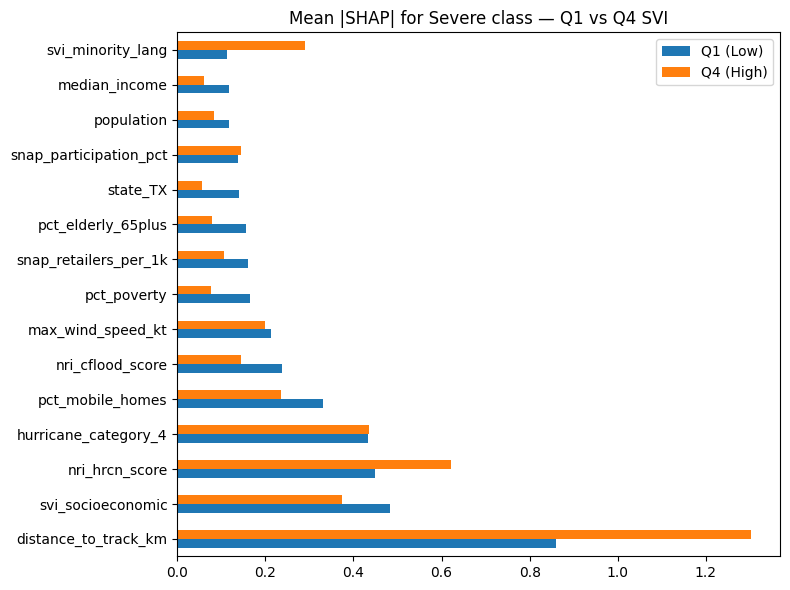

In [10]:
by_grp = shap_mean_abs_by_group(sv_arr[:, :, severe_idx], feat_names, te['svi_q'])
by_grp[['Q1 (Low)', 'Q4 (High)']].head(15).plot(kind='barh', figsize=(8, 6))
plt.title('Mean |SHAP| for Severe class — Q1 vs Q4 SVI')
plt.tight_layout(); plt.savefig(OUT / 'shap_by_svi.png', dpi=150); plt.show()